# Reconstruction Methods Compared

This notebook compares the reconstruction methods in ETSpy on a simulated object whose true
density is known, so that every result can be scored. 

Topics covered:

* What each method does, and its main parameters: filtered backprojection (`"FBP"`), `"SIRT"`,
  `"SART"`, `"DART"`, and the total variation (TV) method`"TVMin"`
* Effects of noise
* The missing wedge from limited tilt range
* How to run the reconstructions on a GPU or on several CPU cores

Note: noise is random, so the absolute numbers produced by this notebook may vary slightly from run to run.

## Imports

In [21]:
%matplotlib inline

import time

import matplotlib.pyplot as plt
import numpy as np
import hyperspy.api as hs
from scipy import ndimage

import etspy.api as tomo
from etspy import simulation as sim

tomo.set_log_level("WARNING")
rng = np.random.default_rng(0)

## Simulation

The object is the cross-section of a needle-shaped specimen, 192 x 192 pixels:

* a round body of density 1
* a dense block of density 2
* three thin bars of density 2, **2, 4 and 8 pixels wide**, to test how well each method keeps
  the size of small features
* a small round particle of density 2

The edges are slightly blurred, as in a real image. The same slice is repeated four times along
the tilt axis, for use with the 3D TVMin method.

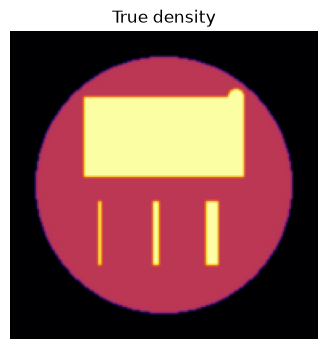

In [22]:
n = 192
yy, xx = np.mgrid[:n, :n] - (n - 1) / 2
obj = np.zeros((n, n), np.float32)
obj[xx**2 + yy**2 < 80**2] = 1.0  # body
obj[(abs(yy + 30) < 25) & (abs(xx) < 50)] = 2.0  # dense block
bar_centres, bar_widths = (-40, -5, 30), (2, 4, 8)
for c, w in zip(bar_centres, bar_widths):  # thin bars
    obj[(abs(yy - 30) < 20) & (abs(xx - c) < w / 2)] = 2.0
obj[(xx - 45) ** 2 + (yy + 55) ** 2 < 5**2] = 2.0  # particle
obj = ndimage.gaussian_filter(obj, 0.7)
model = np.repeat(obj[np.newaxis], 4, axis=0)  # (slices along the tilt axis, y, z)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(obj, cmap="inferno")
ax.set_title("True density")
ax.axis("off");

### Tilt Series and Scores

`create_model_tilt_series` projects the model at the tilts given. Poisson noise is added using the
`dose` paramter which describes the number of counts per unit of projected density; i.e. a higher dose
means less noise.

Two scores are used:

* **error**: the difference from the true density, relative to the true density (0 is
  perfect)
* **widths of the three bars**: the full width at half of the bar's height

In [23]:
def make_series(step=2.0, dose=None, tilt_range=180):
    """Tilt series of the model at uniform steps, with Poisson noise if dose is given."""
    if tilt_range >= 180:
        tilts = np.arange(-90, 90, step)  # 180 deg: -90 and +90 are the same
    else:
        tilts = np.arange(-tilt_range / 2, tilt_range / 2 + step / 2, step)
    series = sim.create_model_tilt_series(model, angles=tilts)
    if dose is not None:
        series.data = rng.poisson(series.data * dose).astype(np.float32) / dose
    return series


def error(rec):
    """Difference from the true density, relative to the true density."""
    return np.linalg.norm(rec.data[1] - obj) / np.linalg.norm(obj)


rows = slice(int(n / 2 + 18), int(n / 2 + 42))


def widths(img):
    """Full width at half height of the three bars (pixels)."""
    profile = img[rows].mean(axis=0)
    out = []
    for c in bar_centres:
        i0 = int(round(c + (n - 1) / 2))
        seg = profile[i0 - 12 : i0 + 13]
        base = np.median(np.r_[seg[:4], seg[-4:]])
        half = (base + seg[10:15].max()) / 2
        above = np.where(seg > half)[0]
        a, b = above[0], above[-1]
        if a == 0 or b == len(seg) - 1:  # no clear bar: no width
            out.append(np.nan)
            continue
        left = a - 1 + (half - seg[a - 1]) / (seg[a] - seg[a - 1])
        right = b + (seg[b] - half) / (seg[b] - seg[b + 1])
        out.append(right - left)
    return np.array(out)


true_widths = widths(obj)
print("true bar widths (px):", np.round(true_widths, 2))

true bar widths (px): [2.38 4.02 8.  ]


## The Methods

| Method | Call | Main parameters | Notes |
|---|---|---|---|
| Filtered backprojection | `reconstruct("FBP")` | `sino_filter` | Fast and linear; streaks and noise with few tilts |
| SIRT | `reconstruct("SIRT", iterations=...)` | `iterations`, `constrain`, `thresh` | Iterative, updates all projections at once, slow to converge |
| SART | `reconstruct("SART", iterations=...)` | `iterations` | Iterative, updates one projection at a time, converges in a few passes |
| TVMin | `reconstruct_tv(iterations=...)` | `iterations`, `tv_weight`,`tv_dims` | Penalizes total variation, assume uniform regions with sharp edges |

`constrain=True` enforces a non-negativity constraint

The helper below runs a set of methods on a series and collects the scores and run times.

In [25]:
quiet = dict(show_progressbar=False)
methods = {
    "FBP": lambda s: s.reconstruct("FBP", **quiet),
    "SIRT (50)": lambda s: s.reconstruct(
        "SIRT", iterations=50, constrain=True, **quiet
    ),
    "SIRT (200)": lambda s: s.reconstruct(
        "SIRT", iterations=200, constrain=True, **quiet
    ),
    "SART (5)": lambda s: s.reconstruct("SART", iterations=5, constrain=True, **quiet),
    "TVMin": lambda s: s.reconstruct_tv(iterations=50, tv_weight=0.1, **quiet),
}


def run_all(series, which=methods):
    results = {}
    for name, method in which.items():
        t0 = time.perf_counter()
        rec = method(series)
        results[name] = dict(
            rec=rec,
            error=error(rec),
            widths=widths(rec.data[1]),
            seconds=time.perf_counter() - t0,
        )
    return results


def show(results, title):
    names = list(results)
    hs.plot.plot_images(
        [hs.signals.Signal2D(obj)]
        + [hs.signals.Signal2D(results[k]["rec"].data[1]) for k in names],
        cmap="inferno",
        vmin=0,
        vmax=2.3,
        per_row=4,
        axes_decor="off",
        colorbar=None,
        label=["Truth"] + names,
    )
    plt.gcf().set_size_inches(12, 7.5)
    plt.gcf().suptitle(title)
    plt.tight_layout()
    print(
        f"{'method':12s} {'error':>6s}   bar widths (true {np.round(true_widths, 1)})   time (s)"
    )
    for k in names:
        r = results[k]
        print(
            f"{k:12s} {r['error']:6.3f}   {np.array2string(r['widths'], precision=1):>28s}"
            f"   {r['seconds']:6.1f}"
        )

## Without Noise

With 90 projections over 180$\degree$ (2$\degree$ steps) and no noise, every method gives a
recognizable object:

* SART is the most accurate followed closely by TVMin
* SIRT keeps improving as it converges (200 iterations are better than 50)
* TVMin is as good as SIRT; both keep the bar widths within about 0.5 pixel

method        error   bar widths (true [2.4 4.  8. ])   time (s)
FBP           0.091                  [2.6 4.1 8. ]      0.0
SIRT (50)     0.059                  [3.7 4.9 8.3]      0.1
SIRT (200)    0.018                  [2.8 4.1 8. ]      0.3
SART (5)      0.012                  [2.5 3.9 7.9]      0.5
TVMin         0.014                  [3.1 4.3 8. ]      0.9


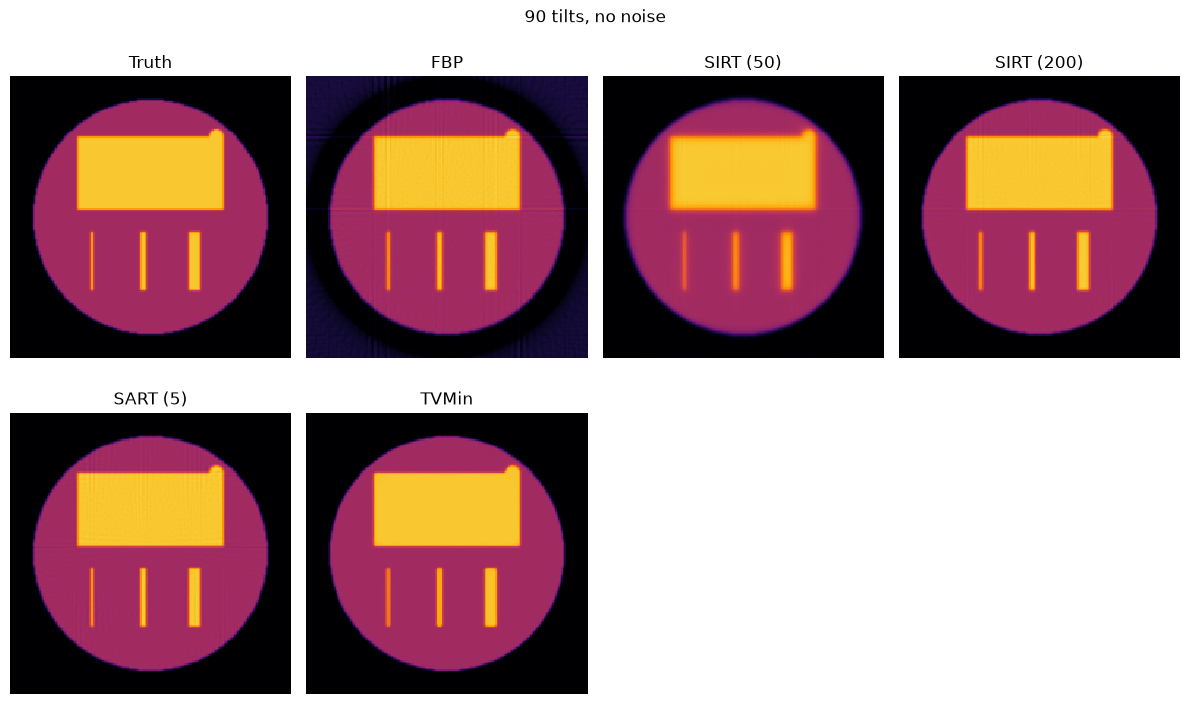

In [26]:
clean = make_series(step=2)
res_clean = run_all(clean)
show(res_clean, "90 tilts, no noise")

## With Noise

Real data are noisy. At a dose of 5 counts per unit of projected density, the ranking changes:

* FBP reproduces the noise in full
* **SIRT stopped at 50 iterations beats SIRT at 200**: SIRT fits the noise last, so running it longer fits more noise
* SART converges much more quickly and is similar to a long SIRT run in this case
* TVMin suppresses the noise best

**NOTE:** TVMin and the short SIRT run suppress noise effectively, but they also widen the bar widths.  By contrast,
the noisier long SIRT run keeps measures width best. Noise suppression and resolution trade against each other, so a
method chosen for the lowest overall error is not necessarily the right one for measuring small features.

method        error   bar widths (true [2.4 4.  8. ])   time (s)
FBP           0.297                  [3.2 4.1 7.5]      0.0
SIRT (50)     0.096                  [4.1 4.7 8.2]      0.1
SIRT (200)    0.191                  [3.3 4.1 7.7]      0.3
SART (5)      0.290                  [3.2 3.9 7.7]      0.5
TVMin         0.054                  [3.6 4.1 8. ]      0.9


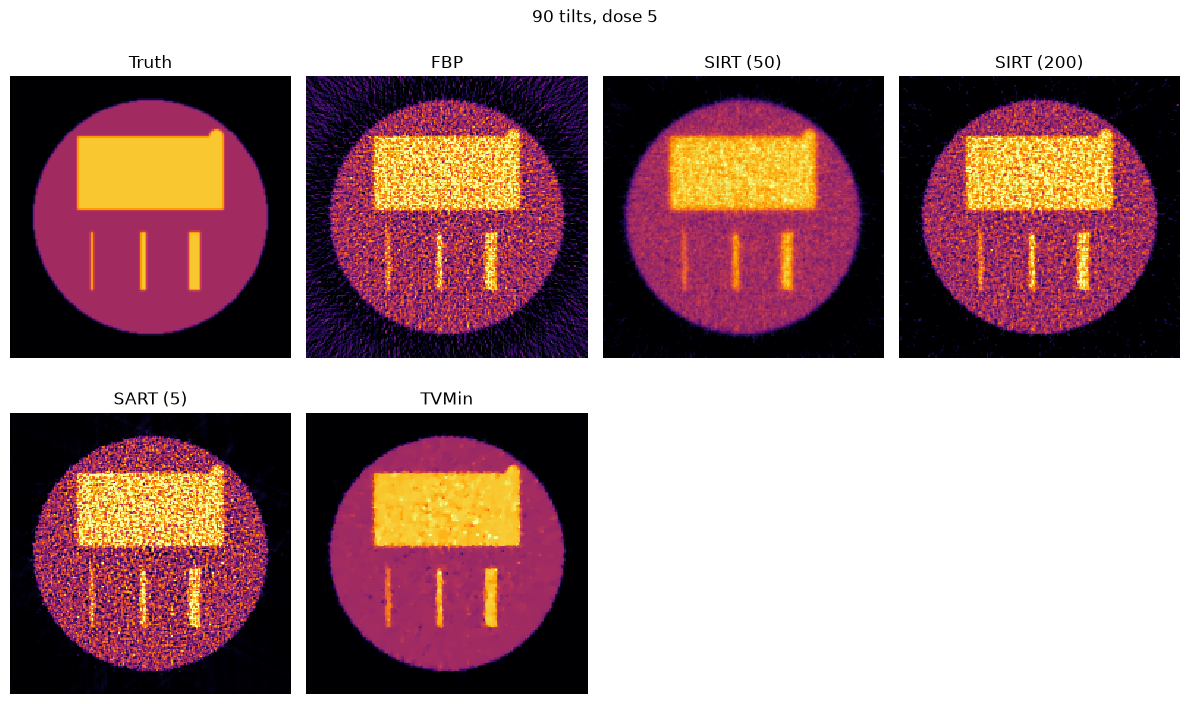

In [27]:
noisy = make_series(step=2, dose=5)
res_noisy = run_all(noisy)
show(res_noisy, "90 tilts, dose 5")

### Choosing the Number of SIRT Iterations

`recon_error` runs SIRT on one slice and keeps the reconstruction and the error (the
difference between the reprojected reconstruction and the data) at every iteration. Here we can
also compute the *true* error at every iteration since the object is known. The data error keeps falling,
while the true error reaches a minimum and then rises as the noise is fitted. On real data only the data error is
available so the stopping criteria is less obvious. A good rule of thumb is to stop where the error descent
starts to slow down.

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 300/300 [00:00<00:00, 1239.70it/s]


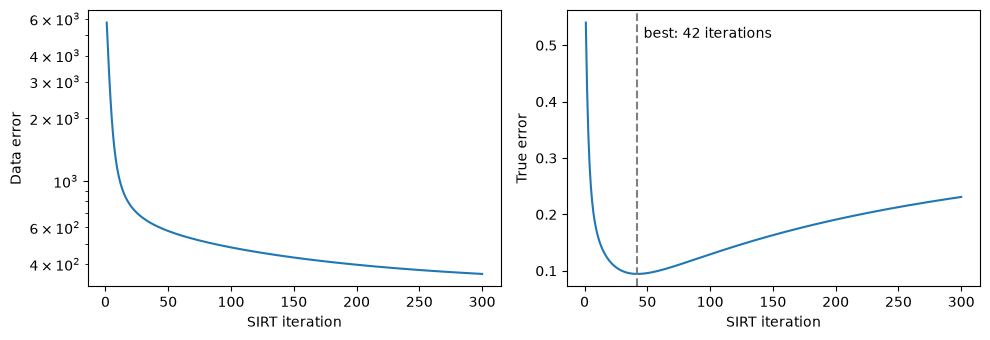

In [28]:
steps, data_error = noisy.recon_error(1, iterations=300)
true_error = [np.linalg.norm(s - obj) / np.linalg.norm(obj) for s in steps.data]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(np.arange(1, 301), data_error.data)
ax[0].set(xlabel="SIRT iteration", ylabel="Data error", yscale="log")
ax[1].plot(np.arange(1, 301), true_error)
best = int(np.argmin(true_error)) + 1
ax[1].axvline(best, ls="--", color="gray")
ax[1].set(xlabel="SIRT iteration", ylabel="True error")
ax[1].text(best + 5, max(true_error) * 0.95, f"best: {best} iterations")
fig.tight_layout()

### The TV Weight

The TVMin weight sets how strongly variation is penalized. If it is too small the noise reduction will be weaker.
If it is too large, the image becomes patchy and small features become difficult to measure. Here the lowest overall error
is at a weight of 0.3, where the measured width of the 2 pixel bar is already almost double the true value.

tv_weight  error   bar widths (true [2.4 4.  8. ])
     0.01  0.245                  [3.1 3.9 7.7]
     0.03  0.175                  [3.2 4.  7.8]
     0.10  0.054                  [3.6 4.1 8. ]
     0.30  0.035                  [4.5 4.7 8.2]
     1.00  0.056                  [7.7 6.1 8.7]


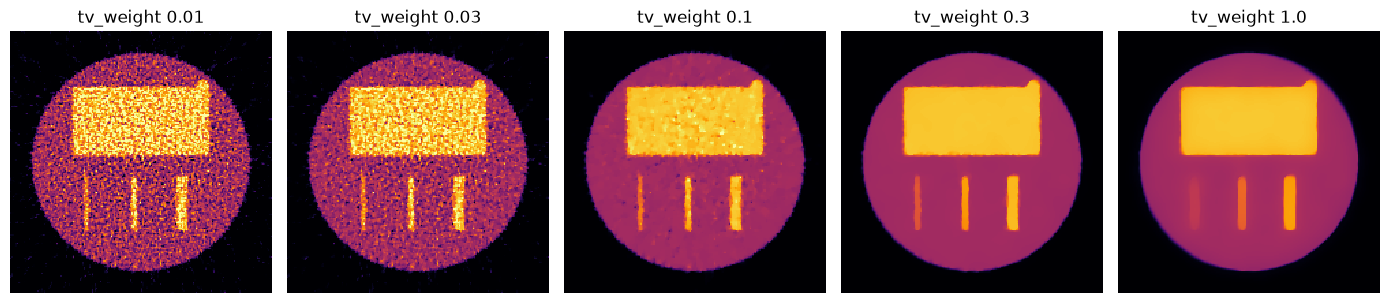

In [29]:
weights = [0.01, 0.03, 0.1, 0.3, 1.0]
tv_runs = {
    w: noisy.reconstruct_tv(iterations=50, tv_weight=w, show_progressbar=False)
    for w in weights
}

hs.plot.plot_images(
    [hs.signals.Signal2D(tv_runs[w].data[1]) for w in weights],
    cmap="inferno",
    vmin=0,
    vmax=2.3,
    per_row=5,
    axes_decor="off",
    colorbar=None,
    label=[f"tv_weight {w}" for w in weights],
)
plt.gcf().set_size_inches(14, 3.4)
plt.tight_layout()

print(f"{'tv_weight':>9s} {'error':>6s}   bar widths (true {np.round(true_widths, 1)})")
for w in weights:
    print(
        f"{w:9.2f} {error(tv_runs[w]):6.3f}   "
        f"{np.array2string(widths(tv_runs[w].data[1]), precision=1):>28s}"
    )

## Fewer Tilts

Fewer projections leave gaps in the data which show as streaks
radiating from the more dense features. Here the dose per projection is kept fixed, so fewer tilts also
means less total dose. FBP degrades fastest and SIRT steadily, while TVMin hardly changes down
to 18 tilts.

**NOTE:** the object in this case consists of uniform regions with sharp edges, which is exactly what TVMin assumes. Real
specimens are rarely that simple, so the advantage will likely be smaller.

FBP        [0.295, 0.41, 0.517, 0.669]
SIRT (50)  [0.096, 0.115, 0.126, 0.134]
TVMin      [0.053, 0.047, 0.048, 0.05]


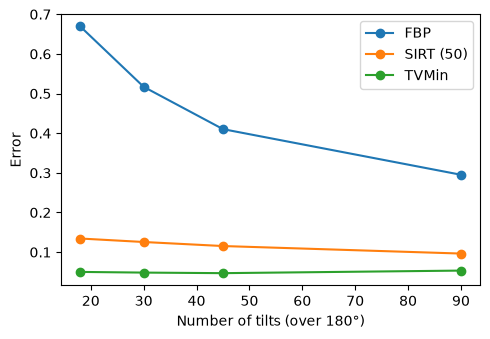

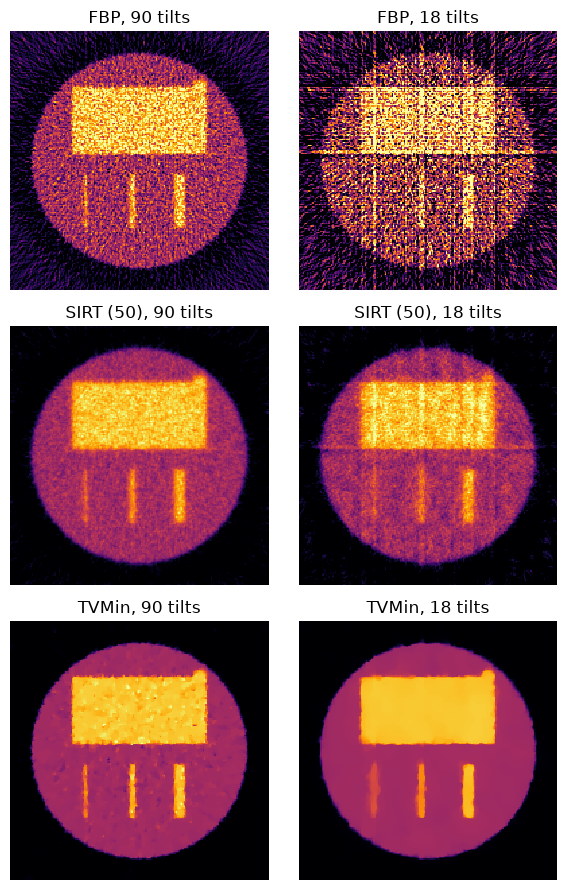

In [30]:
few = {
    "FBP": methods["FBP"],
    "SIRT (50)": methods["SIRT (50)"],
    "TVMin": methods["TVMin"],
}
steps_deg = [2, 4, 6, 10]
sweep = {s: run_all(make_series(step=s, dose=5), few) for s in steps_deg}

fig, ax = plt.subplots(figsize=(5, 3.5))
for name in few:
    ax.plot(
        [180 // s for s in steps_deg],
        [sweep[s][name]["error"] for s in steps_deg],
        "o-",
        label=name,
    )
ax.set(xlabel="Number of tilts (over 180\u00b0)", ylabel="Error")
for name in few:
    print(f"{name:10s}", [round(float(sweep[s][name]["error"]), 3) for s in steps_deg])
ax.legend()
fig.tight_layout()

hs.plot.plot_images(
    [
        hs.signals.Signal2D(sweep[s][name]["rec"].data[1])
        for name in few
        for s in (2, 10)
    ],
    cmap="inferno",
    vmin=0,
    vmax=2.3,
    per_row=2,
    axes_decor="off",
    colorbar=None,
    label=[f"{name}, {180 // s} tilts" for name in few for s in (2, 10)],
)
plt.gcf().set_size_inches(6, 9)
plt.tight_layout()

## Limited Tilt Range: the Missing Wedge

Often in a real experiment, the specimen cannot be tilted over a full 180$\degree$ tilt range. The projections
that are never measured form a *missing wedge* in Fourier space with detrimental results in the reconstruction.
Most notably, anisotropic resolution loss occurs with features along the beam direction being blurred. TVMin
partially fills in this missing information by assuming uniform regions with sharp edges.  This may or may not be
a valid assumption.

method        error   bar widths (true [2.4 4.  8. ])   time (s)
SIRT (50)     0.169                  [3.9 4.5 8.2]      0.1
TVMin         0.076                  [4.3 4.7 8.3]      1.6


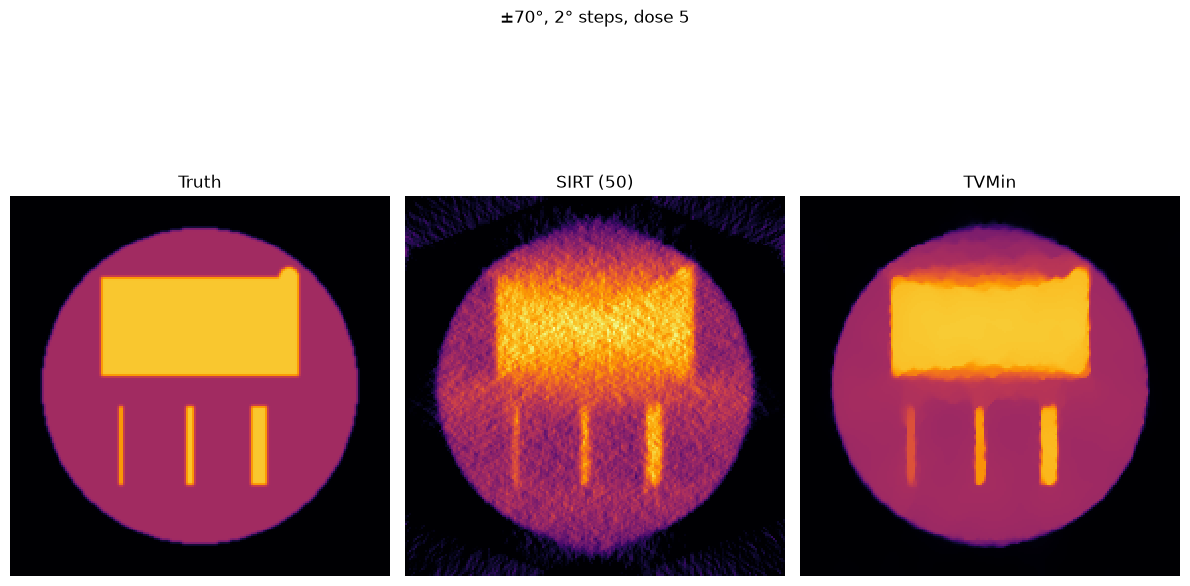

In [34]:
methods = {
    "FBP": lambda s: s.reconstruct("FBP", **quiet),
    "SIRT (50)": lambda s: s.reconstruct(
        "SIRT", iterations=50, constrain=True, **quiet
    ),
    "SIRT (200)": lambda s: s.reconstruct(
        "SIRT", iterations=200, constrain=True, **quiet
    ),
    "SART (5)": lambda s: s.reconstruct("SART", iterations=5, constrain=True, **quiet),
    "TVMin": lambda s: s.reconstruct_tv(iterations=100, tv_weight=0.3, **quiet),
}

wedge = make_series(step=2, dose=5, tilt_range=140)
res_wedge = run_all(
    wedge, {"SIRT (50)": methods["SIRT (50)"], "TVMin": methods["TVMin"]}
)
show(res_wedge, r"$\pm$70$\degree$, 2$\degree$ steps, dose 5")
plt.tight_layout()

## Summary

| Situation | Suggested method |
|---|---|
| Fast, linear, good for alignment checks | FBP, or `test_align` |
| General use | SIRT (choose iteration number with `recon_error`) |
| Noisy data, visualization and segmentation | TVMin (tune `tv_weight`) |
| Measuring small features | SIRT |
| Fewer tilts or a missing wedge | TVMin |

Whatever the method, a reconstruction is only as good as the alignment of the data (see the
[alignment notebook](alignment_in_depth.ipynb))